In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [114]:
class DynamicGraph(nn.Module):
    def __init__(self, feature_dim=64, max_nodes=1024, max_edges_per_node=8, input_size=64, output_size=2, hidden_layers=[128, 256, 256, 128, 64], device=None):
        super().__init__()
        if device==None:
            if hasattr(torch, "xpu") and torch.xpu.is_available():
                device = torch.device("xpu")
            elif torch.cuda.is_available():
                device = torch.device("cuda")
            else:
                device = torch.device("cpu")
        self.device = torch.device(device)
        print(f"\nUsing device : {device}\n")

        self.D = feature_dim
        self.max_nodes = max_nodes
        self.max_edges = max_nodes * max_edges_per_node
        # max_edges = self.max_edges
        self.max_edges_per_node = max_edges_per_node
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_layers = hidden_layers
        self.max_rank = len(hidden_layers)

        ## Node Thingys

        # Node Weights (no_of_nodes,1)
        self.node_weight = nn.Parameter(
            torch.zeros(
                max_nodes,
                feature_dim,
                device=self.device
            )
        )

        # Node Pre Activation(Input of current node) (no_of_nodes,1)
        self.node_pre_activation = nn.Parameter(
            torch.zeros(
                max_nodes,
                feature_dim,
                device=self.device
            )
        )

        # Node Bias (no_of_nodes,1)
        self.node_bias = nn.Parameter(
            torch.randn(
                max_nodes,
                feature_dim,
                device=self.device
            ) * 0.02
        )

        # Node Active/Deactive (no_of_nodes,1)
        self.register_buffer(
            "node_alive",
            torch.zeros(
                max_nodes,
                dtype=torch.bool,
                device=self.device
            )
        )

        # Node Activation Type (Relu/Sigmoid/LRelu) (no_of_nodes,1)
        self.register_buffer(
            "node_activation",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )   
        )

        # Node Out Degree (no_of_nodes,1) (Value ranges from 0 to max_edges_per_node)
        self.register_buffer(
            "out_degree",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )
        )

        # Node In Degree (no_of_nodes,1) (Value ranges from 0 to no_of_nodes * max_edges_per_node)
        self.register_buffer(
            "in_degree",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )
        )

        # Node Rank (no_of_nodes,1)
        # Used to store the rank of nodes, which is used to prevent cycles
        self.register_buffer(
            "node_rank",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )
        )

        # No of current nodes (Includes Active + Deactive)
        self.nodes_count = 0


        ## Edge Thingys

        # Edge Source[edge_source][index] = edge_destination (no_of_nodes,max_edges_per_node)
        self.register_buffer(
            "edge_src",
            -1*torch.ones(
                max_nodes,
                max_edges_per_node,
                dtype=torch.long,
                device=self.device
            )
        )

        # Edge Index[edge_destination][index] = edge_source (no_of_nodes,max_edges_per_node)
        # Used to store the index of edge stored in edge_src matrix for quick operation in back prop
        self.register_buffer(
            "edge_index",
            -1*torch.ones(
                max_nodes,
                max_edges_per_node,
                dtype=torch.long,
                device=self.device
            )
        )

        # Edge Destination[edge_destination][index] = edge_source (no_of_nodes,max_edges_per_node)
        self.register_buffer(
            "edge_dest",
            -1*torch.ones(
                max_nodes,
                max_edges_per_node,
                dtype=torch.long,
                device=self.device
            )
        )

        # Edge Weight[edge_source][edge_destination] (no_of_nodes,max_edges_per_node)
        self.edge_weight = nn.Parameter(
            torch.randn(
                max_nodes,
                max_edges_per_node,
                device=self.device
            ) * 0.02
        )

        # Edge Active/Deactive[edge_source][edge_destination] (no_of_nodes,max_edges_per_node)
        self.register_buffer(
            "edge_alive",
            torch.zeros(
                max_nodes,
                max_edges_per_node,
                dtype=torch.bool,
                device=self.device
            )   
        )

    @torch.no_grad()
    def add_node(self, activation=1):
        if self.nodes_count >= self.max_nodes:
            raise RuntimeError("Node capacity reached in Add Node"+str(self.max_nodes))
        index = self.nodes_count
        self.node_alive[index] = True
        self.node_activation[index] = activation
        self.nodes_count += 1
        return index

    @torch.no_grad()
    def remove_node(self, index):
        if index>=self.nodes_count or index<0:
            raise RuntimeError("Out of bound in Remove Node")

        self.node_alive[index] = False

    @torch.no_grad()
    def add_edge(self, source, destination):
        if source<0 or source>=self.nodes_count or destination<0 or destination>=self.nodes_count:
            raise RuntimeError("Out of bound in Add Edge 1st Thingy")
        if self.out_degree[source]>=self.max_edges_per_node or self.in_degree[destination]>=self.max_edges_per_node:
            raise RuntimeError("Out of bound in Add Edge 2nd Thingy")
        self.edge_src[source][self.out_degree[source]] = destination

        self.edge_index[destination][self.in_degree[destination]] = self.out_degree[source]
        self.edge_dest[destination][self.in_degree[destination]] = source

        self.edge_alive[source][self.out_degree[source]] = True

        self.out_degree[source] += 1
        self.in_degree[destination] += 1

    @torch.no_grad()
    def remove_edge(self, source, destination):
        if source<0 or source>=self.nodes_count or destination<0 or destination>=self.nodes_count:
            raise RuntimeError("Out of bound in Remove Edge")
        temp_index = self.edge_src[source]==destination
        self.edge_alive[source][temp_index] = False

    @torch.no_grad()
    def random_sample_thingy(self, start_index, end_index, target_size, sample_mode="destination"):
        destination_idx = torch.zeros(target_size,dtype=torch.long,device=self.device)
        temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

        if sample_mode=="destination":
            temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
        else:
            temp_idx = temp_idx[start_index:end_index][self.out_degree[start_index:end_index]<self.max_edges_per_node-1]
        
        temp_idx = temp_idx[torch.randperm(len(temp_idx))]
        destination_idx[:min(len(temp_idx),target_size)] = temp_idx[:target_size]
        if sample_mode=="destination":
            # self.in_degree[temp_idx[:target_size]]+=1
            self.in_degree.index_add_(0,temp_idx[:target_size],torch.ones_like(temp_idx[:target_size]))
        else:
            # self.out_degree[temp_idx[:target_size]]+=1
            self.out_degree.index_add_(0,temp_idx[:target_size],torch.ones_like(temp_idx[:target_size]))
        
        current_size = min(len(temp_idx),target_size)
        current_target_size = target_size - current_size
        while current_size!=target_size:
            if current_size==0:
                print("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
                raise RuntimeError("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
            
            temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

            if sample_mode=="destination":
                temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
            else:
                temp_idx = temp_idx[start_index:end_index][self.out_degree[start_index:end_index]<self.max_edges_per_node-1]
            
            temp_idx = temp_idx[torch.randperm(len(temp_idx))]
            if len(temp_idx) == 0:
                print("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
                raise RuntimeError("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
            
            destination_idx[current_size:current_size + min(current_target_size,len(temp_idx))] = temp_idx[:current_target_size]
            if sample_mode=="destination":
                # self.in_degree[temp_idx[:current_target_size]]+=1
                self.in_degree.index_add_(0,temp_idx[:current_target_size],torch.ones_like(temp_idx[:current_target_size]))
            else:
                # self.out_degree[temp_idx[:current_target_size]]+=1
                self.out_degree.index_add_(0,temp_idx[:current_target_size],torch.ones_like(temp_idx[:current_target_size]))

            current_size += min(current_target_size,len(temp_idx))
            current_target_size = target_size - current_size
            
        return destination_idx


    @torch.no_grad()
    def initialize_graph(self):
        total_layers = sum(self.hidden_layers)
        if total_layers>self.max_nodes:
            raise RuntimeError("More no of hidden thingys in Initialize Graph")
        
        current_count = 0
        temp_layers = self.hidden_layers.copy()
        print(temp_layers)
        output_layer_count = temp_layers.pop()
        print(temp_layers)
        for i in range(len(temp_layers)):
            layer_count = temp_layers[i]
            self.node_activation[current_count:current_count+layer_count] = 1
            self.node_rank[current_count:current_count+layer_count] = i+1
            current_count += layer_count
        self.node_activation[current_count:current_count+output_layer_count] = 2
        self.node_rank[current_count:current_count+output_layer_count] = len(self.hidden_layers)
        self.node_alive[:total_layers] = True
        self.nodes_count = total_layers

        # temp_idx = torch.randint(
        #     self.hidden_layers[0],
        #     self.nodes_count,
        #     source_idx.shape,
        #     device=self.device
        # )
        # temp_idx = torch.unique(temp_idx)
        # destination_idx = temp_idx[self.in_degree[temp_idx]<self.max_edges_per_node-1][:self.hidden_layers[0]]
        # while destination_idx.shape != source_idx.shape:
        #     temp_idx = torch.randint(
        #         self.hidden_layers[0],
        #         self.nodes_count,
        #         source_idx.shape,
        #         device=self.device
        #     )
        #     temp_idx = torch.unique(temp_idx)
        #     destination_idx = temp_idx[self.in_degree[temp_idx]<self.max_edges_per_node-1][:self.hidden_layers[0]]


        # temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)
        # temp_idx = temp_idx[self.hidden_layers[0]:][self.node_alive[self.hidden_layers[0]:]]
        # destination_idx = temp_idx[torch.randperm(len(temp_idx))[:self.hidden_layers[0]]]

        # source_idx = torch.randperm(
        #     self.hidden_layers[0],
        #     device=self.device
        # )
        # destination_idx = self.random_sample_thingy(
        #     self.hidden_layers[0],
        #     total_layers,
        #     self.hidden_layers[0]
        # )
        # self.edge_src[source_idx, self.out_degree[source_idx]] = destination_idx
        # self.in_degree[destination_idx] += 1
        current_count = 0
        for i in range(len(self.hidden_layers)-1):
            source_idx = torch.randperm(
                self.hidden_layers[i],
                device=self.device
            )
            source_idx += current_count

            destination_idx = self.random_sample_thingy(
                self.hidden_layers[i]+current_count,
                total_layers,
                self.hidden_layers[i],
                sample_mode="destination"
            )
            current_count += self.hidden_layers[i]
            # self.out_degree[source_idx] -= 1
            # self.in_degree[destination_idx] -= 1
            # self.out_degree.index_add_(
            #     0,
            #     source_idx,
            #     -1*torch.ones_like(source_idx)
            # )
            self.in_degree.index_add_(
                0,
                destination_idx,
                -1*torch.ones_like(destination_idx)
            )

            self.edge_src[source_idx, self.out_degree[source_idx]] = destination_idx
            self.edge_index[destination_idx, self.in_degree[destination_idx]] = self.out_degree[source_idx]
            self.edge_dest[destination_idx, self.in_degree[destination_idx]] = source_idx
            # self.out_degree[source_idx] += 1
            # self.in_degree[destination_idx] += 1
            self.out_degree.index_add_(
                0,
                source_idx,
                torch.ones_like(source_idx)
            )
            self.in_degree.index_add_(
                0,
                destination_idx,
                torch.ones_like(destination_idx)
            )
            
        current_count = self.hidden_layers[0]
        for i in range(1,len(self.hidden_layers)):
            destination_idx = torch.randperm(
                self.hidden_layers[i],
                device=self.device
            )
            destination_idx += current_count
            print(destination_idx)

            source_idx = self.random_sample_thingy(
                0,
                current_count,
                self.hidden_layers[i],
                sample_mode="source"
            )
            print("Source:",source_idx)
            current_count += self.hidden_layers[i]
            # self.out_degree[source_idx] -= 1
            # self.in_degree[destination_idx] -= 1
            self.out_degree.index_add_(
                0,
                source_idx,
                -1*torch.ones_like(source_idx)
            )
            # self.in_degree.index_add_(
            #     0,
            #     destination_idx,
            #     -1*torch.ones_like(destination_idx)
            # )

            self.edge_src[source_idx, self.out_degree[source_idx]] = destination_idx
            self.edge_index[destination_idx, self.in_degree[destination_idx]] = self.out_degree[source_idx]
            self.edge_dest[destination_idx, self.in_degree[destination_idx]] = source_idx
            # self.out_degree[source_idx] += 1
            # self.in_degree[destination_idx] += 1
            self.out_degree.index_add_(
                0,
                source_idx,
                torch.ones_like(source_idx)
            )
            self.in_degree.index_add_(
                0,
                destination_idx,
                torch.ones_like(destination_idx)
            )

        
        


In [3]:
torch.randperm(5)

tensor([3, 0, 2, 1, 4])

In [4]:
# temp = DynamicGraph(2,10,2)
temp = DynamicGraph(2,1024)
# node0 = temp.add_node()
# node1 = temp.add_node()
# node2 = temp.add_node()

# temp.add_edge(node0,node2)
# temp.add_edge(node0,node1)
# temp.remove_edge(node0,node2)

# temp.remove_node(node1)

print(temp.node_alive)



Using device : xpu

tensor([False, False, False,  ..., False, False, False], device='xpu:0')


In [5]:
# print(temp.in_degree[130:])
temp = DynamicGraph(2,1024)
temp.initialize_graph()
temp1 = temp.node_rank
print(temp1)


Using device : xpu

[128, 256, 256, 128, 64]
[128, 256, 256, 128]
tensor([171, 165, 317, 380, 312, 167, 257, 151, 359, 140, 244, 337, 188, 205,
        308, 246, 369, 276, 294, 330, 218, 166, 185, 232, 222, 132, 201, 189,
        318, 154, 361, 162, 272, 273, 219, 283, 281, 146, 267, 163, 133, 239,
        214, 169, 161, 347, 358, 233, 291, 374, 285, 176, 210, 341, 305, 301,
        263, 215, 270, 170, 292, 158, 293, 307, 311, 173, 316, 298, 376, 332,
        334, 203, 249, 303, 227, 224, 187, 360, 128, 300, 275, 196, 367, 363,
        238, 172, 323, 250, 153, 345, 217, 290, 138, 148, 256, 130, 319, 186,
        181, 286, 156, 299, 179, 310, 355, 261, 383, 175, 254, 372, 208, 190,
        348, 265, 212, 248, 240, 279, 152, 134, 150, 247, 260, 131, 229, 278,
        284, 356, 191, 336, 365, 304, 371, 364, 352, 234, 168, 258, 302, 206,
        382, 241, 182, 288, 335, 160, 177, 237, 349, 192, 193, 183, 329, 268,
        251, 327, 306, 333, 136, 314, 320, 274, 180, 139, 157, 184, 280, 22

In [6]:
import torch
import networkx as nx
import matplotlib.pyplot as plt


def visualize_edge_src(edge_src, hidden_layers):
    """
    Visualize edge_src as an adjacency-list graph.

    Parameters
    ----------
    edge_src : torch.Tensor
        Shape: [num_nodes, max_edges_per_node]
        edge_src[source, i] = destination
        -1 means no edge.

    hidden_layers : list[int]
        Number of nodes in each layer.

        Example:
            [5, 5, 5, 3]

        means:

            Layer 1: nodes 0  - 4
            Layer 2: nodes 5  - 9
            Layer 3: nodes 10 - 14
            Layer 4: nodes 15 - 17
    """

    edge_src = edge_src.detach().cpu()

    G = nx.DiGraph()

    # --------------------------------------------------
    # Create edges
    # --------------------------------------------------

    for source in range(edge_src.shape[0]):

        for destination in edge_src[source]:

            destination = destination.item()

            # Ignore unused entries
            if destination == -1:
                continue

            G.add_edge(source, destination)

    # --------------------------------------------------
    # Create positions based on hidden_layers
    # --------------------------------------------------

    pos = {}

    current_node = 0

    # Space between layers
    layer_spacing = 3.0

    # Create each layer
    for layer, num_nodes in enumerate(hidden_layers):

        x = layer * layer_spacing

        # Center nodes vertically
        y_start = (num_nodes - 1) / 2

        for i in range(num_nodes):

            node = current_node + i

            y = y_start - i

            pos[node] = (x, y)

        current_node += num_nodes

    # --------------------------------------------------
    # Draw
    # --------------------------------------------------

    plt.figure(figsize=(12, 8))

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_size=1200,
        arrows=True,
        arrowsize=20,
        font_size=10
    )

    # --------------------------------------------------
    # Draw layer labels
    # --------------------------------------------------

    current_node = 0

    for layer, num_nodes in enumerate(hidden_layers):

        x = layer * layer_spacing

        # Middle of this layer
        y = 0

        if num_nodes > 0:
            y = (num_nodes - 1) / 2 + 1.0

        plt.text(
            x,
            y,
            f"Layer {layer + 1}",
            ha="center",
            fontsize=12
        )

        current_node += num_nodes

    plt.title("DynamicGraph - edge_src")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


Using device : xpu

[5, 5, 5, 2]
[5, 5, 5]
tensor([8, 7, 6, 5, 9], device='xpu:0')
Source: tensor([3, 4, 1, 0, 2], device='xpu:0')
tensor([11, 13, 10, 14, 12], device='xpu:0')
Source: tensor([0, 7, 1, 4, 3], device='xpu:0')
tensor([15, 16], device='xpu:0')
Source: tensor([ 0, 11], device='xpu:0')
tensor([1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 4, 4, 0, 0, 0],
       device='xpu:0')
5
Edge Dest
 tensor([[-1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -1],
        [ 0, -1, -1, -1, -1],
        [ 4,  1, -1, -1, -1],
        [ 4, -1, -1, -1, -1],
        [ 3, -1, -1, -1, -1],
        [ 2,  2, -1, -1, -1],
        [ 1,  5,  1, -1, -1],
        [ 9,  0, -1, -1, -1],
        [ 3, -1, -1, -1, -1],
        [ 3,  6,  7, -1, -1],
        [ 0,  7,  4, -1, -1],
        [14, -1,  0, -1, -1],
        [ 8, 11, -1, -1, 11],
        [-1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -

/tmp/ipykernel_58970/1415885533.py:124: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


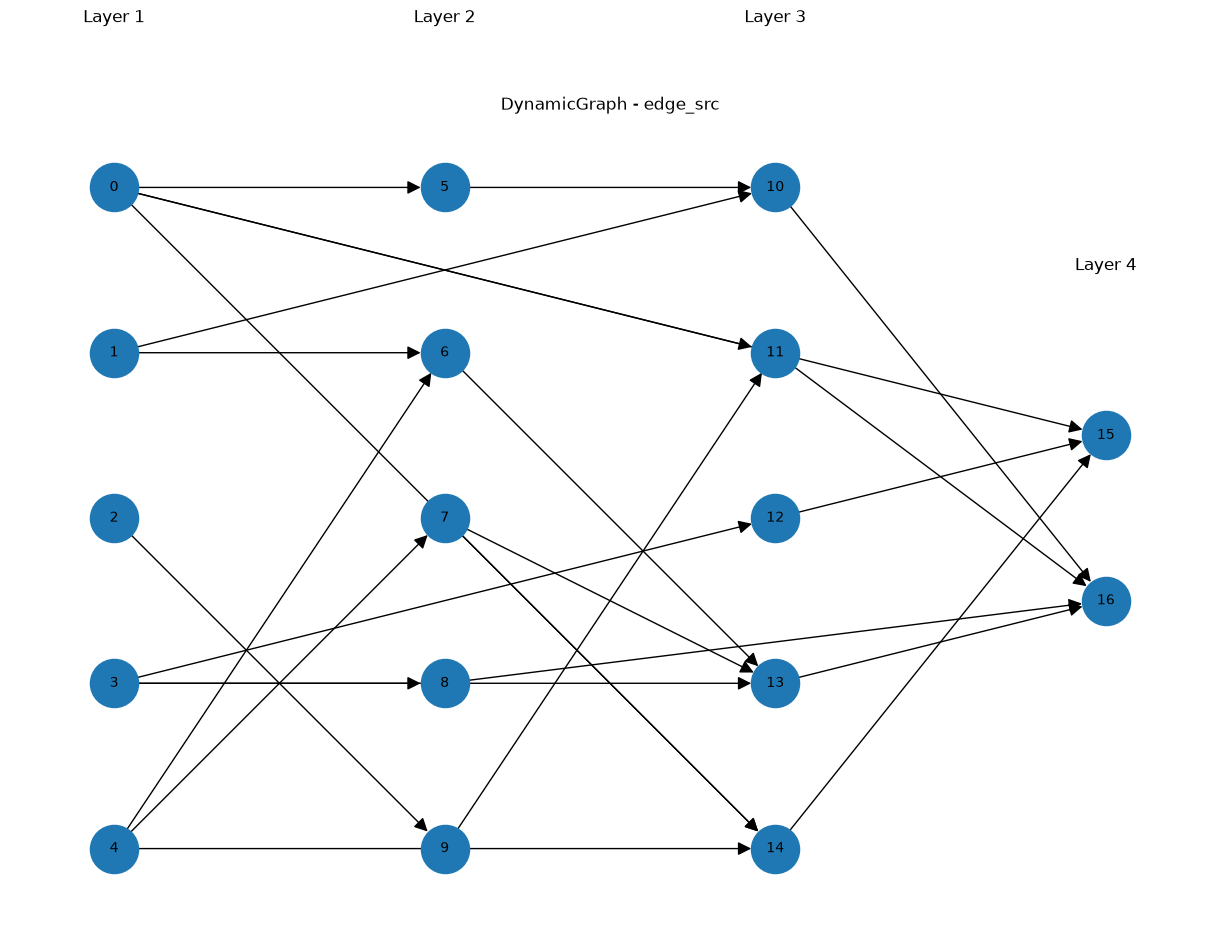

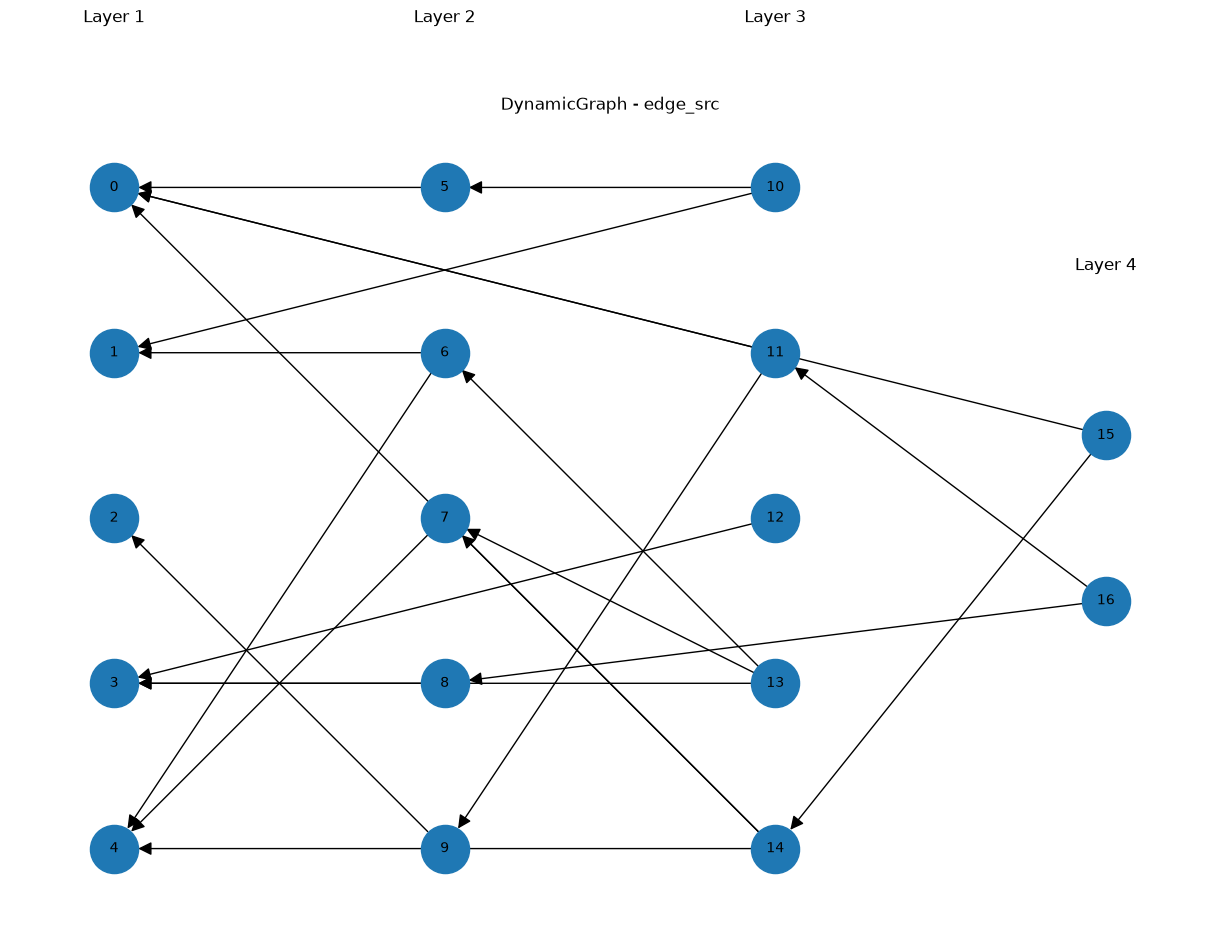

In [180]:
# print(temp.in_degree[130:])
hidden_layers = [5,5,5,2]
temp = DynamicGraph(2,20,hidden_layers=hidden_layers,max_edges_per_node=5,device="xpu")
temp.initialize_graph()
temp1 = temp.node_rank
print(temp1)
print(temp.max_edges_per_node)
# print("Edge Src\n",temp.edge_src)
print("Edge Dest\n",temp.edge_dest)
# print("Indegree",temp.in_degree)
# print("Outdegree",temp.out_degree)
visualize_edge_src(temp.edge_src,hidden_layers)
visualize_edge_src(temp.edge_dest,hidden_layers)